# Importing necessary libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

#Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load the dataset
data = pd.read_csv("/content/drive/MyDrive/Big data and iot/Project/Final Code/FInal Project File/weather.csv")

data.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,12/1/2008,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,12/2/2008,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,12/3/2008,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,12/4/2008,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,12/5/2008,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23530 entries, 0 to 23529
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           23530 non-null  object 
 1   Location       23530 non-null  object 
 2   MinTemp        23242 non-null  float64
 3   MaxTemp        23390 non-null  float64
 4   Rainfall       23290 non-null  float64
 5   Evaporation    9432 non-null   float64
 6   Sunshine       6664 non-null   float64
 7   WindGustDir    20130 non-null  object 
 8   WindGustSpeed  20132 non-null  float64
 9   WindDir9am     20771 non-null  object 
 10  WindDir3pm     21881 non-null  object 
 11  WindSpeed9am   23018 non-null  float64
 12  WindSpeed3pm   22362 non-null  float64
 13  Humidity9am    23205 non-null  float64
 14  Humidity3pm    22533 non-null  float64
 15  Pressure9am    20172 non-null  float64
 16  Pressure3pm    20173 non-null  float64
 17  Cloud9am       14119 non-null  float64
 18  Cloud3

In [ ]:
# Summary statistics
print(data.describe())

            MinTemp       MaxTemp      Rainfall  Evaporation     Sunshine  \
count  23242.000000  23390.000000  23290.000000  9432.000000  6664.000000   
mean      13.352612     23.960402      2.704770     5.825138     7.811945   
std        5.858070      6.105407      9.841985     4.871567     3.718698   
min       -3.300000      6.800000      0.000000     0.000000     0.000000   
25%        9.000000     19.500000      0.000000     3.000000     5.500000   
50%       14.100000     23.400000      0.000000     4.800000     8.900000   
75%       18.000000     27.675000      0.800000     7.200000    10.600000   
max       29.700000     47.300000    371.000000    86.200000    14.000000   

       WindGustSpeed  WindSpeed9am  WindSpeed3pm   Humidity9am  Humidity3pm  \
count   20132.000000  23018.000000  22362.000000  23205.000000  22533.00000   
mean       38.122492     13.046485     17.089035     69.360267     52.91346   
std        13.126753      9.173207      9.129422     17.663034     21

In [ ]:
data.columns

Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RISK_MM', 'RainTomorrow'],
      dtype='object')

#Null Vlue Visualization & Elimination

<Axes: >

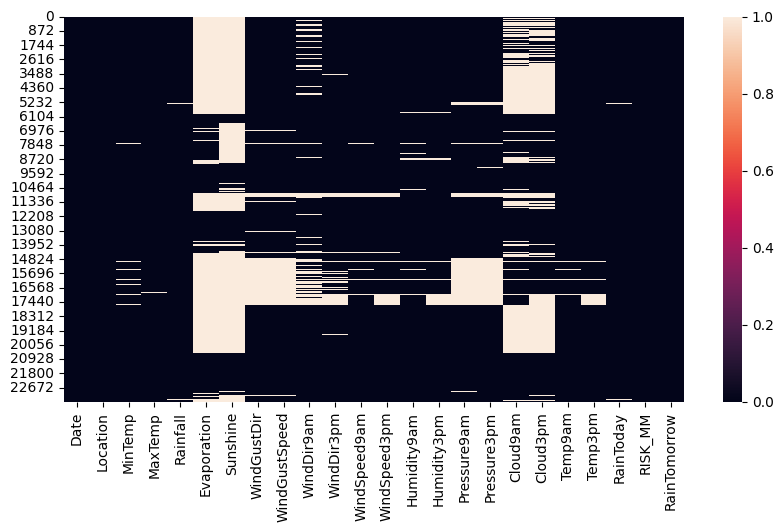

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(data.isnull())

In [ ]:
null_var = data.isnull().sum()/data.shape[0]*100
null_var

Date              0.000000
Location          0.000000
MinTemp           1.223969
MaxTemp           0.594985
Rainfall          1.019975
Evaporation      59.915002
Sunshine         71.678708
WindGustDir      14.449639
WindGustSpeed    14.441139
WindDir9am       11.725457
WindDir3pm        7.008075
WindSpeed9am      2.175946
WindSpeed3pm      4.963876
Humidity9am       1.381215
Humidity3pm       4.237144
Pressure9am      14.271143
Pressure3pm      14.266893
Cloud9am         39.995750
Cloud3pm         41.287718
Temp9am           0.811730
Temp3pm           3.642159
RainToday         1.019975
RISK_MM           0.000000
RainTomorrow      0.000000
dtype: float64

In [ ]:
drop_columns = null_var[null_var >45].keys()
drop_columns

Index(['Evaporation', 'Sunshine'], dtype='object')

In [ ]:
data=data.drop(columns=drop_columns)

In [ ]:
data.shape

(23530, 22)

<Axes: >

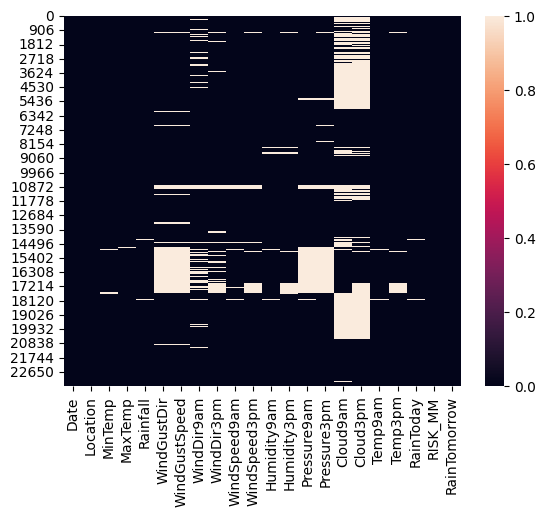

In [ ]:
sns.heatmap(data.isnull())

In [ ]:
# Calculate the null value percentages for each column
null_percentages = (data.isnull().sum() / len(data)) * 100

null_percentages

Date              0.000000
Location          0.000000
MinTemp           1.223969
MaxTemp           0.594985
Rainfall          1.019975
WindGustDir      14.449639
WindGustSpeed    14.441139
WindDir9am       11.725457
WindDir3pm        7.008075
WindSpeed9am      2.175946
WindSpeed3pm      4.963876
Humidity9am       1.381215
Humidity3pm       4.237144
Pressure9am      14.271143
Pressure3pm      14.266893
Cloud9am         39.995750
Cloud3pm         41.287718
Temp9am           0.811730
Temp3pm           3.642159
RainToday         1.019975
RISK_MM           0.000000
RainTomorrow      0.000000
dtype: float64

In [ ]:
# Identify columns where null value percentage is greater than 10%
columns_to_drop = null_percentages[null_percentages > 15].index

# Filter the DataFrame to keep only rows where the selected columns are not null
data = data.dropna(subset=columns_to_drop)

<Axes: >

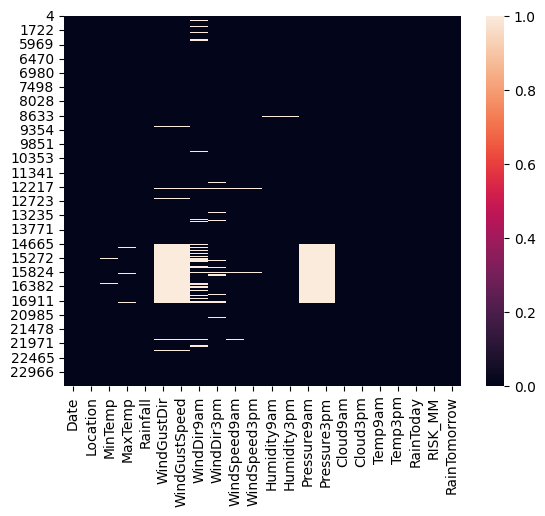

In [ ]:
sns.heatmap(data.isnull())

In [ ]:
data[0:].fillna(data.mean(), inplace=True)

<ipython-input-84-e69c293cbabb>:1: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  data[0:].fillna(data.mean(), inplace=True)


<Axes: >

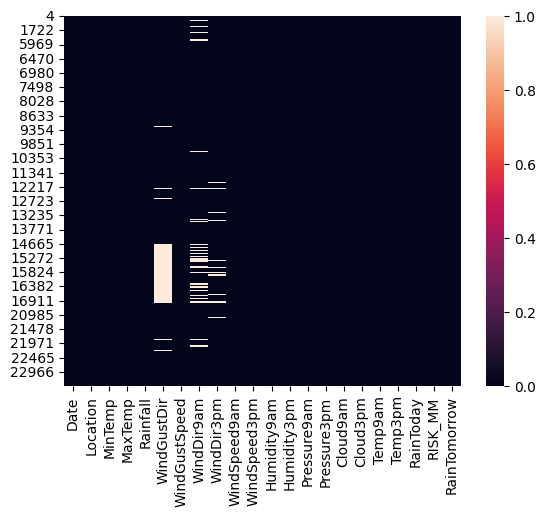

In [ ]:
sns.heatmap(data.isnull())

In [ ]:
# Convert categorical columns to numerical using label encoding
categorical_cols = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
label_encoder = LabelEncoder()
for col in categorical_cols:
    data[col] = label_encoder.fit_transform(data[col])

<Axes: >

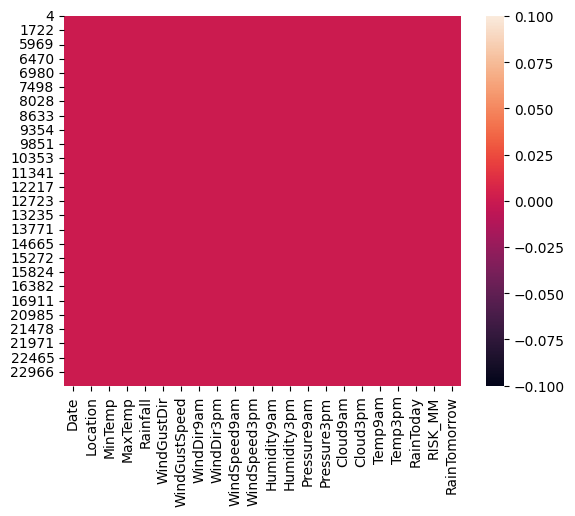

In [ ]:
sns.heatmap(data.isnull())

In [ ]:
# Drop unnecessary columns
data.drop([ 'Date'], axis=1, inplace=True)

#Normalization

In [ ]:
# Normalize numeric features
numeric_cols = ['MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'WindSpeed9am',
                'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am',
                'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RISK_MM']
data[numeric_cols] = (data[numeric_cols] - data[numeric_cols].mean()) / data[numeric_cols].std()

In [ ]:
data

,Location,MinTemp,MaxTemp,Rainfall,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
4,0,0.615050,1.377926,-0.187976,13,0.139423,1,7,-0.856039,0.297560,...,-0.900117,-1.239462,-1.692253,0.940135,1.316210,-0.118195,1.216864,0,-0.261610,0
11,0,0.337018,-0.350034,-0.077442,5,-0.761973,4,1,0.026887,-0.471945,...,1.728268,-1.292857,-2.019263,1.278048,1.316210,-0.471891,-0.907214,1,1.165850,1
12,0,0.337018,-0.855381,1.156857,13,1.942215,6,6,1.461641,1.176995,...,1.818902,-4.176167,-4.053993,1.278048,1.316210,-0.192657,-1.107914,1,0.053543,1
15,0,0.024232,-0.480446,-0.280088,1,-1.573230,11,0,-0.414576,-0.911662,...,1.320415,-0.990287,-0.892895,1.278048,-1.266512,-0.229888,-0.723239,0,1.277081,1
16,0,-0.080030,-0.154416,1.267391,13,2.122494,3,14,-0.966405,0.297560,...,0.550026,-2.129372,-2.382607,1.278048,-1.266512,-0.080964,-0.154588,1,0.702389,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23525,5,0.545542,-0.398939,0.862099,13,-0.040856,14,13,-0.193845,0.517419,...,1.456366,-1.435242,-1.474246,0.264311,0.578289,0.216886,-0.388738,1,-0.150379,1
23526,5,0.615050,-0.545652,-0.151131,8,1.130958,15,12,1.461641,1.176995,...,1.773585,-1.702215,-1.728587,1.278048,1.316210,0.235501,-0.505813,1,-0.076226,1
23527,5,0.545542,-0.659763,-0.077442,11,1.491517,11,8,1.020178,1.506783,...,0.867245,-0.830103,-0.638553,1.278048,0.209329,-0.025117,-0.756689,1,-0.261610,0
23528,5,0.093740,-0.741270,-0.261666,12,0.409842,12,12,0.468349,0.957136,...,0.640660,-0.420744,-0.438714,0.940135,-0.897552,-0.229888,-0.739964,0,0.072082,1


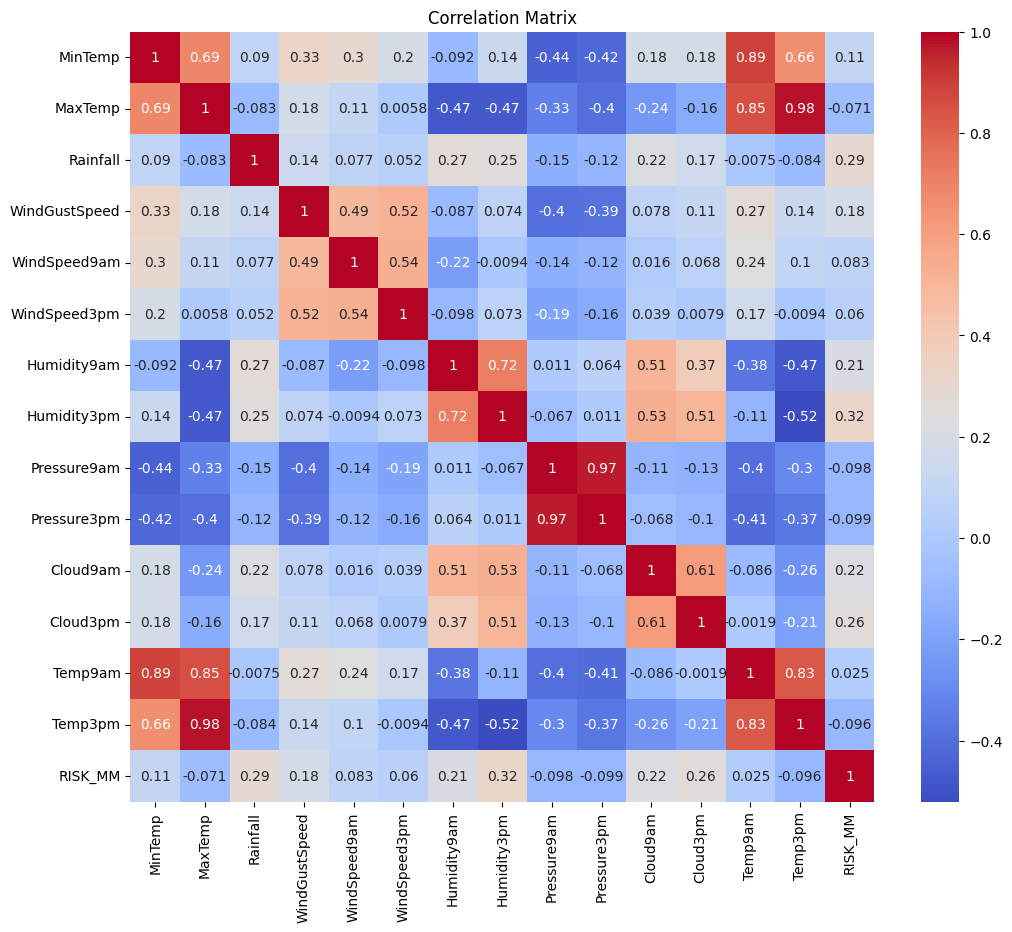

In [ ]:
# Correlation matrix

numeric_data = data[numeric_cols]
corr_matrix = numeric_data.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

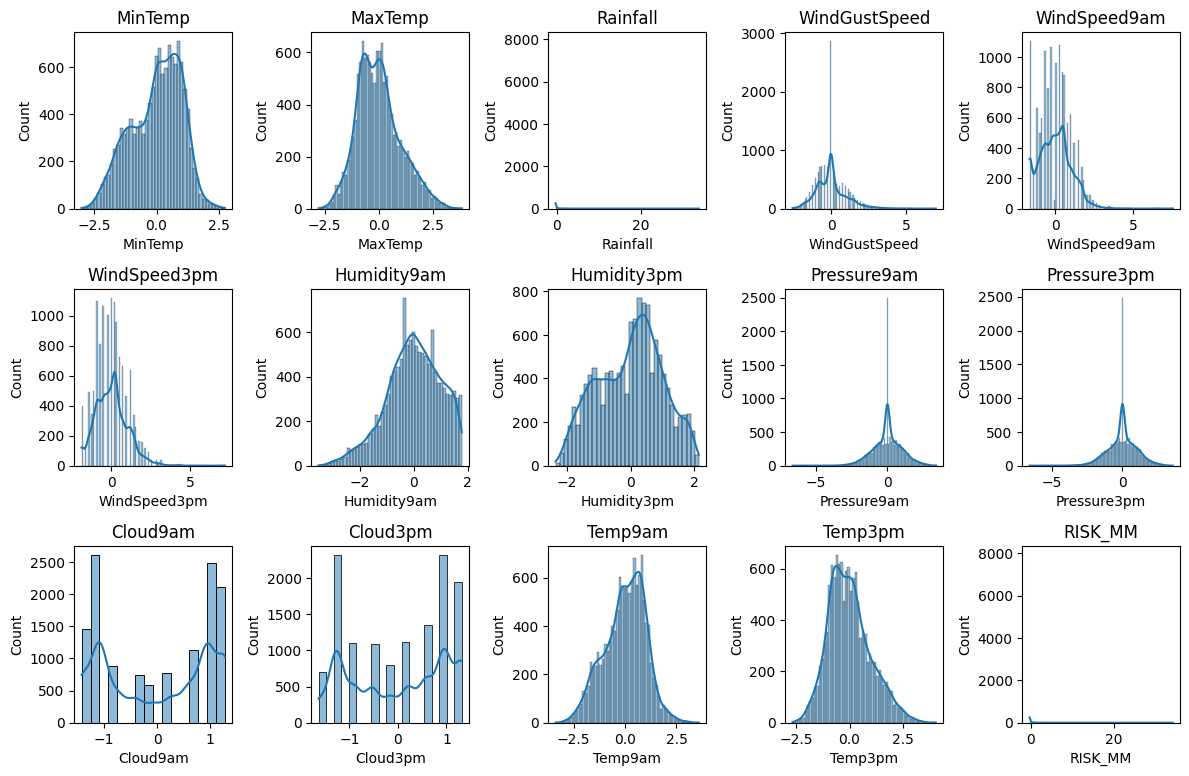

In [ ]:
# Distribution of numeric features
plt.figure(figsize=(12, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(4, 5, i+1)
    sns.histplot(data[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

# Encode categorical variables

In [ ]:
categorical_cols = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
data = pd.get_dummies(data, columns=categorical_cols, drop_first=True)

In [ ]:
# Split the dataset into features and target variable
X = data.drop('RainTomorrow', axis=1)  # Features
y = data['RainTomorrow']  # Target variable

In [ ]:
X.columns

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'WindSpeed9am',
       'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am',
       'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RISK_MM',
       'Location_1', 'Location_2', 'Location_3', 'Location_4', 'Location_5',
       'WindGustDir_1', 'WindGustDir_2', 'WindGustDir_3', 'WindGustDir_4',
       'WindGustDir_5', 'WindGustDir_6', 'WindGustDir_7', 'WindGustDir_8',
       'WindGustDir_9', 'WindGustDir_10', 'WindGustDir_11', 'WindGustDir_12',
       'WindGustDir_13', 'WindGustDir_14', 'WindGustDir_15', 'WindGustDir_16',
       'WindDir9am_1', 'WindDir9am_2', 'WindDir9am_3', 'WindDir9am_4',
       'WindDir9am_5', 'WindDir9am_6', 'WindDir9am_7', 'WindDir9am_8',
       'WindDir9am_9', 'WindDir9am_10', 'WindDir9am_11', 'WindDir9am_12',
       'WindDir9am_13', 'WindDir9am_14', 'WindDir9am_15', 'WindDir9am_16',
       'WindDir3pm_1', 'WindDir3pm_2', 'WindDir3pm_3', 'WindDir3pm_4',
       'WindDir3pm_5', 'WindDir3p

# Perform PCA for feature extraction

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=10)  # Specify the desired number of components
X_pca = pca.fit_transform(X)

# Convert the PCA components to a DataFrame
X_pca_df = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(X_pca.shape[1])])

# Concatenate the PCA components with the existing features
X_with_pca = pd.concat([X.reset_index(drop=True), X_pca_df], axis=1)

#Split Dataset

In [ ]:
# Split the dataset with PCA components into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_with_pca, y, test_size=0.2, random_state=42)

In [ ]:
X_pca_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,1.757977,1.104758,-1.473809,1.049040,-0.978000,0.723642,0.777908,0.560929,1.116001,-0.448620
1,-0.801183,3.120015,-1.366809,1.132029,-0.579752,0.852074,-0.220030,-1.426447,-0.109344,-0.285613
2,1.421098,5.430508,1.123755,4.018870,-1.112560,0.063100,0.744142,-0.741158,-0.629008,0.360279
3,-0.909207,0.789029,-1.322403,0.899581,0.147616,0.272492,-0.903906,-1.944683,0.481898,-0.723969
4,0.924900,2.609275,-0.085021,3.079613,0.751959,-0.658612,-0.326449,0.826919,0.699371,-0.904809
...,...,...,...,...,...,...,...,...,...,...
12772,-0.023150,2.684494,-0.509115,1.232572,-0.419973,-1.223247,0.049796,-0.855912,-0.019613,0.213661
12773,0.481139,3.927593,0.970537,0.793029,-1.587592,-0.242800,0.030296,-0.573770,-0.375945,-0.188464
12774,0.166907,2.497145,1.747784,0.298546,-1.088307,-0.547790,0.006848,0.188694,0.174520,-0.259918
12775,-0.427814,1.056697,1.218137,0.462496,-0.590028,-0.545214,-0.499915,-0.445153,0.519554,-0.479314


In [ ]:
X_train.columns

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'WindSpeed9am',
       'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am',
       'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RISK_MM',
       'Location_1', 'Location_2', 'Location_3', 'Location_4', 'Location_5',
       'WindGustDir_1', 'WindGustDir_2', 'WindGustDir_3', 'WindGustDir_4',
       'WindGustDir_5', 'WindGustDir_6', 'WindGustDir_7', 'WindGustDir_8',
       'WindGustDir_9', 'WindGustDir_10', 'WindGustDir_11', 'WindGustDir_12',
       'WindGustDir_13', 'WindGustDir_14', 'WindGustDir_15', 'WindGustDir_16',
       'WindDir9am_1', 'WindDir9am_2', 'WindDir9am_3', 'WindDir9am_4',
       'WindDir9am_5', 'WindDir9am_6', 'WindDir9am_7', 'WindDir9am_8',
       'WindDir9am_9', 'WindDir9am_10', 'WindDir9am_11', 'WindDir9am_12',
       'WindDir9am_13', 'WindDir9am_14', 'WindDir9am_15', 'WindDir9am_16',
       'WindDir3pm_1', 'WindDir3pm_2', 'WindDir3pm_3', 'WindDir3pm_4',
       'WindDir3pm_5', 'WindDir3p

#Apply Classification Algorithmn

In [ ]:
# Initialize the RandomForestClassifier
rf_classifier = RandomForestClassifier(random_state=42)

# Train the model with PCA components
rf_classifier.fit(X_train, y_train)

# Make predictions on the test set with PCA components
y_pred_rf = rf_classifier.predict(X_test)

# Evaluate the model with PCA components
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test,y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_rf)
cv_scores_rf = cross_val_score(rf_classifier, X, y, cv=5, scoring='accuracy')
misclassification_error_rf = 1 - accuracy_rf
confusion_mat = confusion_matrix(y_test, y_pred_rf)

# Print the evaluation metrics with PCA components
print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1 Score:", f1_rf)
print("ROC AUC Score:", roc_auc_rf)
print("Cross-validated scores:", cv_scores_rf)
print("Mean Cross-validated score:", np.mean(cv_scores_rf))
print("Misclassification Error:", misclassification_error_rf)

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC AUC Score: 1.0
Cross-validated scores: [1.         1.         1.         0.96555773 0.99960861]
Mean Cross-validated score: 0.9930332681017614
Misclassification Error: 0.0


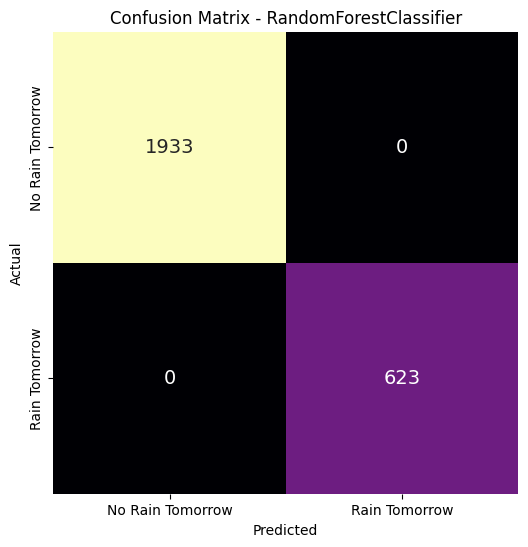

In [ ]:
# Display confusion matrix for RandomForestClassifier as a heatmap
plt.figure(figsize=(6, 6))
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='magma', cbar=False,
            annot_kws={'size': 14},
            xticklabels=['No Rain Tomorrow', 'Rain Tomorrow'],
            yticklabels=['No Rain Tomorrow', 'Rain Tomorrow'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - RandomForestClassifier')
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

In [ ]:
# Logistic Regression
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred_log_reg = log_reg.predict(X_test)

# Evaluate Logistic Regression
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)
precision_log_reg = precision_score(y_test, y_pred_log_reg)
recall_log_reg = recall_score(y_test, y_pred_log_reg)
f1_log_reg = f1_score(y_test, y_pred_log_reg)
roc_auc_log_reg = roc_auc_score(y_test, y_pred_log_reg)
cv_scores_log_reg = cross_val_score(log_reg, X, y, cv=5, scoring='accuracy')
misclassification_error_log_reg = 1 - accuracy_log_reg
confusion_mat_log_reg = confusion_matrix(y_test, y_pred_log_reg)

print("Logistic Regression Metrics:")
print("Accuracy:", accuracy_log_reg)
print("Precision:", precision_log_reg)
print("Recall:", recall_log_reg)
print("F1 Score:", f1_log_reg)
print("ROC AUC Score:", roc_auc_log_reg)
print("Cross-validated scores:", cv_scores_log_reg)
print("Mean Cross-validated score:", np.mean(cv_scores_log_reg))
print("Misclassification Error:", misclassification_error_log_reg)

Logistic Regression Metrics:
Accuracy: 0.9890453834115805
Precision: 0.998324958123953
Recall: 0.956661316211878
F1 Score: 0.9770491803278688
ROC AUC Score: 0.9780719928188205
Cross-validated scores: [0.978482   0.98004695 0.97181996 0.91037182 0.93894325]
Mean Cross-validated score: 0.9559327961681812
Misclassification Error: 0.010954616588419452


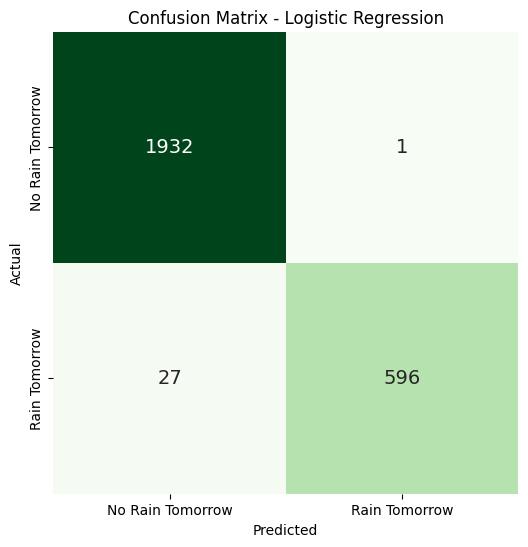

In [ ]:
# Display confusion matrix for Logistic Regression as a heatmap
plt.figure(figsize=(6, 6))
sns.heatmap(confusion_mat_log_reg, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={'size': 14},
            xticklabels=['No Rain Tomorrow', 'Rain Tomorrow'],
            yticklabels=['No Rain Tomorrow', 'Rain Tomorrow'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [ ]:
# Support Vector Machine (SVM)
svm_classifier = SVC(random_state=42)
svm_classifier.fit(X_train, y_train)
y_pred_svm = svm_classifier.predict(X_test)

# Evaluate SVM
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_pred_svm)
misclassification_error_svm = 1 - accuracy_svm
cv_scores_svm = cross_val_score(svm_classifier, X, y, cv=5, scoring='accuracy')
confusion_mat_svm = confusion_matrix(y_test, y_pred_svm)

print("\nSupport Vector Machine (SVM) Metrics:")
print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1 Score:", f1_svm)
print("ROC AUC Score:", roc_auc_svm)
print("Cross-validated scores:", cv_scores_svm)
print("Mean Cross-validated score:", np.mean(cv_scores_svm))
print("Misclassification Error:", misclassification_error_rf)


Support Vector Machine (SVM) Metrics:
Accuracy: 0.9499217527386542
Precision: 0.9787234042553191
Recall: 0.812199036918138
F1 Score: 0.8877192982456141
ROC AUC Score: 0.9032542003007659
Cross-validated scores: [0.94092332 0.95226917 0.94481409 0.59021526 0.70136986]
Mean Cross-validated score: 0.8259183410968092
Misclassification Error: 0.0


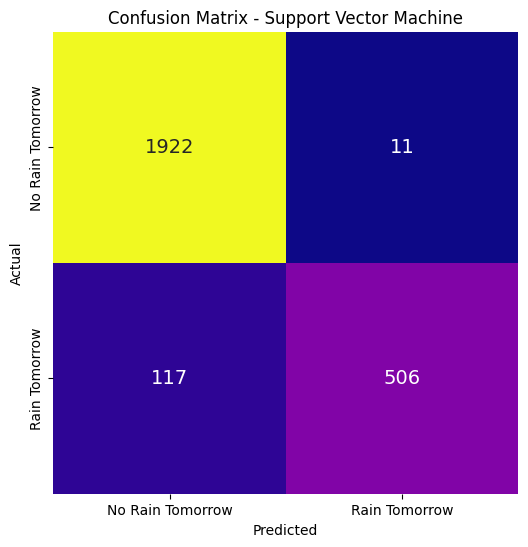

In [ ]:
# Display confusion matrix for Support Vector Machine as a heatmap
plt.figure(figsize=(6, 6))
sns.heatmap(confusion_mat_svm, annot=True, fmt='d', cmap='plasma', cbar=False,
            annot_kws={'size': 14},
            xticklabels=['No Rain Tomorrow', 'Rain Tomorrow'],
            yticklabels=['No Rain Tomorrow', 'Rain Tomorrow'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Support Vector Machine')
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# K-Nearest Neighbors (KNN)
knn_classifier = KNeighborsClassifier()
knn_classifier.fit(X_train, y_train)
y_pred_knn = knn_classifier.predict(X_test)

# Evaluate K-Nearest Neighbors
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_pred_knn)
misclassification_error_knn = 1 - accuracy_knn
cv_scores_knn = cross_val_score(knn_classifier, X, y, cv=5, scoring='accuracy')
confusion_mat_knn = confusion_matrix(y_test, y_pred_knn)

print("\nK-Nearest Neighbors (KNN) Metrics:")
print("Accuracy:", accuracy_knn)
print("Precision:", precision_knn)
print("Recall:", recall_knn)
print("F1 Score:", f1_knn)
print("ROC AUC Score:", roc_auc_knn)
print("Cross-validated scores:", cv_scores_knn)
print("Mean Cross-validated score:", np.mean(cv_scores_knn))
print("Misclassification Error:", misclassification_error_knn)


K-Nearest Neighbors (KNN) Metrics:
Accuracy: 0.8615023474178404
Precision: 0.7930283224400871
Recall: 0.5842696629213483
F1 Score: 0.6728280961182993
ROC AUC Score: 0.7675616291844197
Cross-validated scores: [0.85837246 0.85915493 0.85362035 0.47514677 0.49667319]
Mean Cross-validated score: 0.7085935399306034
Misclassification Error: 0.13849765258215962


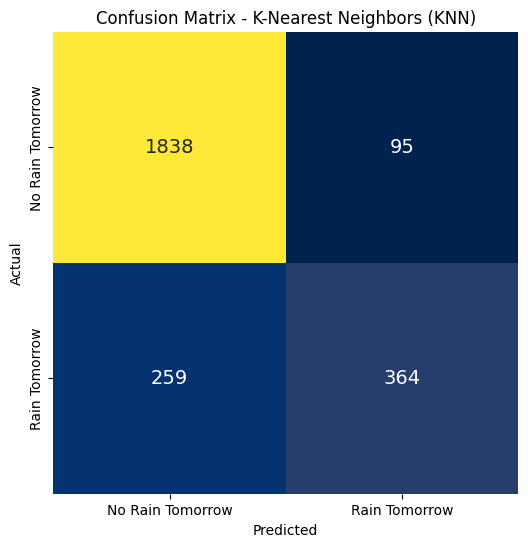

In [ ]:
# Display confusion matrix for K-Nearest Neighbors as a heatmap
plt.figure(figsize=(6, 6))
sns.heatmap(confusion_mat_knn, annot=True, fmt='d', cmap='cividis', cbar=False,
            annot_kws={'size': 14},
            xticklabels=['No Rain Tomorrow', 'Rain Tomorrow'],
            yticklabels=['No Rain Tomorrow', 'Rain Tomorrow'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - K-Nearest Neighbors (KNN)')
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier
# Decision Trees
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(X_train, y_train)
y_pred_dt = dt_classifier.predict(X_test)

# Evaluate Decision Trees
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_pred_dt)
misclassification_error_dt = 1 - accuracy_dt
cv_scores_dt = cross_val_score(dt_classifier, X, y, cv=5, scoring='accuracy')
confusion_mat_dt = confusion_matrix(y_test, y_pred_dt)

print("\nDecision Trees Metrics:")
print("Accuracy:", accuracy_dt)
print("Precision:", precision_dt)
print("Recall:", recall_dt)
print("F1 Score:", f1_dt)
print("ROC AUC Score:", roc_auc_dt)
print("Cross-validated scores:", cv_scores_dt)
print("Mean Cross-validated score:", np.mean(cv_scores_dt))
print("Misclassification Error:", misclassification_error_dt)


Decision Trees Metrics:
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC AUC Score: 1.0
Cross-validated scores: [1.         1.         1.         1.         0.99960861]
Mean Cross-validated score: 0.999921722113503
Misclassification Error: 0.0


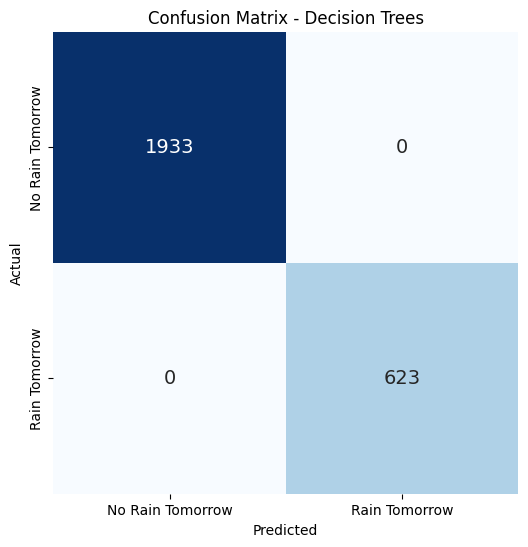

In [ ]:
# Display confusion matrix for Decision Trees as a heatmap
plt.figure(figsize=(6, 6))
sns.heatmap(confusion_mat_dt, annot=True, fmt='d', cmap='Blues', cbar=False,
            annot_kws={'size': 14},
            xticklabels=['No Rain Tomorrow', 'Rain Tomorrow'],
            yticklabels=['No Rain Tomorrow', 'Rain Tomorrow'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Decision Trees')
plt.show()

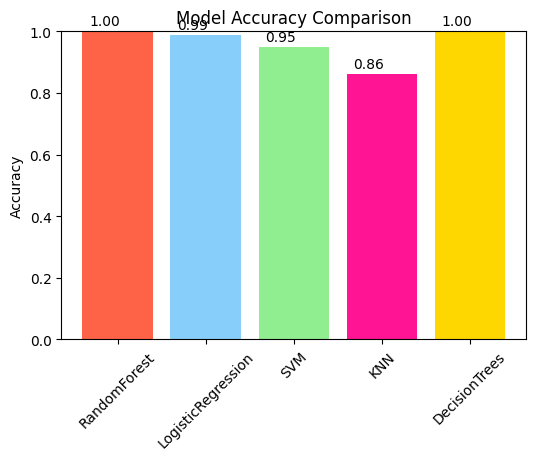

In [ ]:
model_names = ['RandomForest', 'LogisticRegression', 'SVM', 'KNN', 'DecisionTrees']
accuracies = [accuracy_rf, accuracy_log_reg, accuracy_svm, accuracy_knn, accuracy_dt]

colors = ['#FF6347', '#87CEFA', '#90EE90', '#FF1493', '#FFD700']

# Create a bar chart to compare accuracies
plt.figure(figsize=(6, 4))
bars = plt.bar(model_names, accuracies, color=colors)
plt.ylim(0, 1.0)  # Set the y-axis range to 0-1
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.xticks(rotation=45)  # Rotate x-axis labels for better readability

# Add labels on top of each bar
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2 - 0.15, bar.get_height() + 0.02, f'{acc:.2f}', ha='center')

plt.show()


In [ ]:
classification_reports = {
    'Model': ['RandomForest', 'LogisticRegression', 'SVM', 'KNN', 'DecisionTrees'],
    'Accuracy': [accuracy_rf, accuracy_log_reg, accuracy_svm, accuracy_knn, accuracy_dt],
    'Precision': [precision_rf, precision_log_reg, precision_svm, precision_knn, precision_dt],
    'Recall': [recall_rf, recall_log_reg, recall_svm, recall_knn, recall_dt],
    'F1 Score': [f1_rf, f1_log_reg, f1_svm, f1_knn, f1_dt],
    'ROC AUC': [roc_auc_rf, roc_auc_log_reg, roc_auc_svm, roc_auc_knn, roc_auc_dt]
}

# Create a DataFrame from the dictionary
comparison_df = pd.DataFrame(classification_reports)

# Display the comparison table
print(comparison_df)


                Model  Accuracy  Precision    Recall  F1 Score   ROC AUC
0        RandomForest  1.000000   1.000000  1.000000  1.000000  1.000000
1  LogisticRegression  0.989045   0.998325  0.956661  0.977049  0.978072
2                 SVM  0.949922   0.978723  0.812199  0.887719  0.903254
3                 KNN  0.861502   0.793028  0.584270  0.672828  0.767562
4       DecisionTrees  1.000000   1.000000  1.000000  1.000000  1.000000


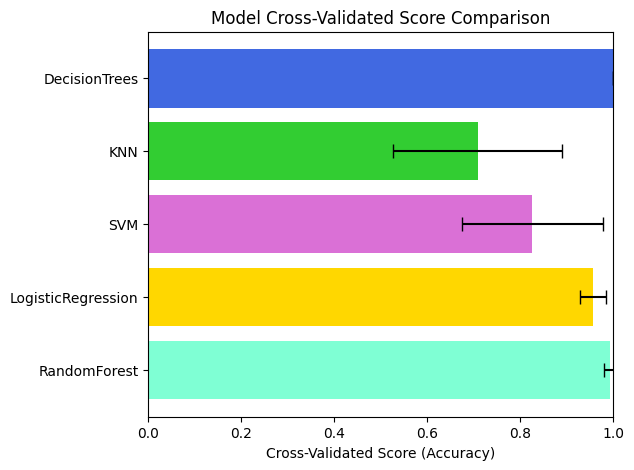

In [ ]:
model_names = ['RandomForest', 'LogisticRegression', 'SVM', 'KNN', 'DecisionTrees']
cross_val_scores = [cv_scores_rf, cv_scores_log_reg, cv_scores_svm, cv_scores_knn, cv_scores_dt]
cross_val_std = [scores.std() for scores in cross_val_scores]
colors = ['#7FFFD4', '#FFD700', '#DA70D6', '#32CD32', '#4169E1']

# Create a horizontal bar chart with error bars to compare cross-validated scores
plt.figure(figsize=(6,5))
plt.barh(model_names, [np.mean(scores) for scores in cross_val_scores], xerr=cross_val_std, color=colors, capsize=5)
plt.xlim(0, 1.0)  # Set the x-axis range to 0-1
plt.xlabel('Cross-Validated Score (Accuracy)')
plt.title('Model Cross-Validated Score Comparison')
plt.show()


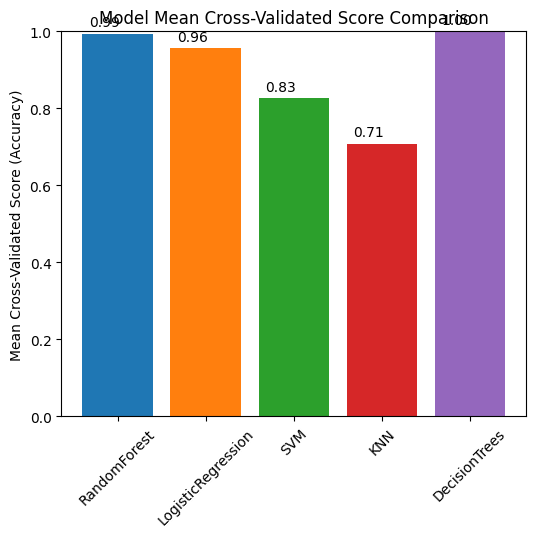

In [ ]:
model_names = ['RandomForest', 'LogisticRegression', 'SVM', 'KNN', 'DecisionTrees']
mean_cv_scores = [np.mean(cv_scores_rf), np.mean(cv_scores_log_reg), np.mean(cv_scores_svm), np.mean(cv_scores_knn), np.mean(cv_scores_dt)]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

# Create a bar chart to compare mean cross-validated scores
plt.figure(figsize=(6, 5))
bars = plt.bar(model_names, mean_cv_scores, color=colors)
plt.ylim(0, 1.0)  # Set the y-axis range to 0-1
plt.ylabel('Mean Cross-Validated Score (Accuracy)')
plt.title('Model Mean Cross-Validated Score Comparison')
plt.xticks(rotation=45)  # Rotate x-axis labels for better readability

# Add labels on top of each bar
for bar, score in zip(bars, mean_cv_scores):
    plt.text(bar.get_x() + bar.get_width() / 2 - 0.15, bar.get_height() + 0.02, f'{score:.2f}', ha='center')

plt.show()


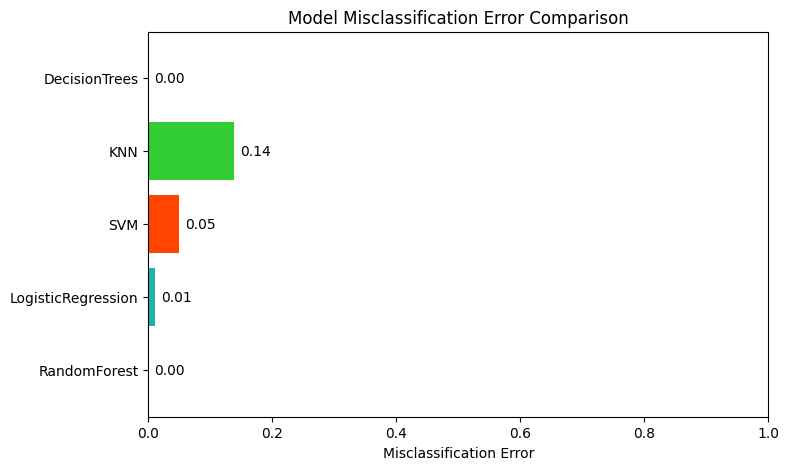

In [ ]:
model_names = ['RandomForest', 'LogisticRegression', 'SVM', 'KNN', 'DecisionTrees']
misclassification_errors = [1 - accuracy_rf, 1 - accuracy_log_reg, 1 - accuracy_svm, 1 - accuracy_knn, 1 - accuracy_dt]
colors = ['#8A2BE2', '#20B2AA', '#FF4500', '#32CD32', '#9932CC']

# Create a horizontal bar chart to compare misclassification errors
plt.figure(figsize=(8, 5))
bars = plt.barh(model_names, misclassification_errors, color=colors)
plt.xlim(0, 1.0)  # Set the x-axis range to 0-1
plt.xlabel('Misclassification Error')
plt.title('Model Misclassification Error Comparison')

# Add labels on the right side of each bar
for bar, error in zip(bars, misclassification_errors):
    plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f'{error:.2f}', va='center')

plt.show()



In [ ]:
from sklearn.metrics import jaccard_score

# List of model names and their corresponding predicted labels
model_names = ['RandomForest', 'LogisticRegression', 'SVM', 'KNN', 'DecisionTrees']
predicted_labels = [y_pred_rf, y_pred_log_reg, y_pred_svm, y_pred_knn, y_pred_dt]

# List of true labels (y_test) for all models
true_labels = [y_test] * len(model_names)

# Calculate and print Jaccard scores for each model
for name, predicted, true in zip(model_names, predicted_labels, true_labels):
    jaccard = jaccard_score(true, predicted)
    print(f"Jaccard Score for {name}: {jaccard:.4f}")


Jaccard Score for RandomForest: 1.0000
Jaccard Score for LogisticRegression: 0.9551
Jaccard Score for SVM: 0.7981
Jaccard Score for KNN: 0.5070
Jaccard Score for DecisionTrees: 1.0000


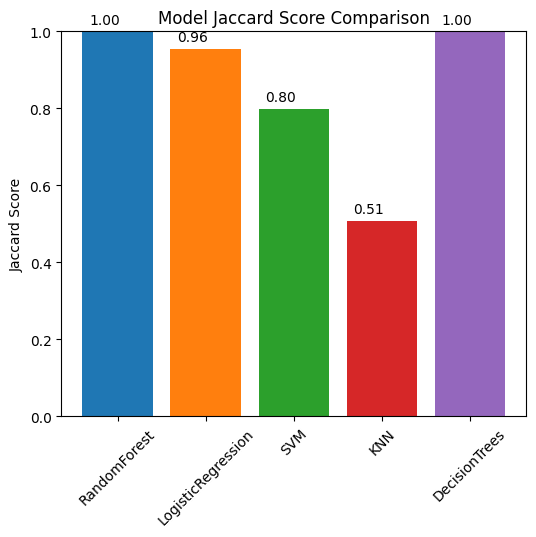

In [ ]:
from sklearn.metrics import jaccard_score

# List of model names and their corresponding Jaccard scores
model_names = ['RandomForest', 'LogisticRegression', 'SVM', 'KNN', 'DecisionTrees']
jaccard_scores = [jaccard_score(y_test, y_pred_rf),
                  jaccard_score(y_test, y_pred_log_reg),
                  jaccard_score(y_test, y_pred_svm),
                  jaccard_score(y_test, y_pred_knn),
                  jaccard_score(y_test, y_pred_dt)]

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

# Create a bar chart to compare Jaccard scores
plt.figure(figsize=(6,5))
bars = plt.bar(model_names, jaccard_scores, color=colors)
plt.ylim(0, 1.0)  # Set the y-axis range to 0-1
plt.ylabel('Jaccard Score')
plt.title('Model Jaccard Score Comparison')
plt.xticks(rotation=45)  # Rotate x-axis labels for better readability

# Add labels on top of each bar
for bar, score in zip(bars, jaccard_scores):
    plt.text(bar.get_x() + bar.get_width() / 2 - 0.15, bar.get_height() + 0.02, f'{score:.2f}', ha='center')

plt.show()


In [ ]:
model_names = ['RandomForest', 'LogisticRegression', 'SVM', 'KNN', 'DecisionTrees']

# List of Cross-validated scores, Misclassification Error, and Jaccard scores for each model
cross_validated_scores = [np.mean(cv_scores_rf), np.mean(cv_scores_log_reg), np.mean(cv_scores_svm), np.mean(cv_scores_knn), np.mean(cv_scores_dt)]
misclassification_errors = [1 - accuracy_rf, 1 - accuracy_log_reg, 1 - accuracy_svm, 1 - accuracy_knn, 1 - accuracy_dt]
jaccard_scores = [jaccard_score(y_test, y_pred_rf), jaccard_score(y_test, y_pred_log_reg), jaccard_score(y_test, y_pred_svm), jaccard_score(y_test, y_pred_knn), jaccard_score(y_test, y_pred_dt)]

# Create a DataFrame to display the metrics
comparison_df = pd.DataFrame({
    'Model': model_names,
    'Cross-Validated Score': cross_validated_scores,
    'Misclassification Error': misclassification_errors,
    'Jaccard Score': jaccard_scores
})

# Set the 'Model' column as the index
comparison_df.set_index('Model', inplace=True)

# Display the comparison table
print(comparison_df)


                    Cross-Validated Score  Misclassification Error  \
Model                                                                
RandomForest                     0.993033                 0.000000   
LogisticRegression               0.955933                 0.010955   
SVM                              0.825918                 0.050078   
KNN                              0.708594                 0.138498   
DecisionTrees                    0.999922                 0.000000   

                    Jaccard Score  
Model                              
RandomForest             1.000000  
LogisticRegression       0.955128  
SVM                      0.798107  
KNN                      0.506964  
DecisionTrees            1.000000  


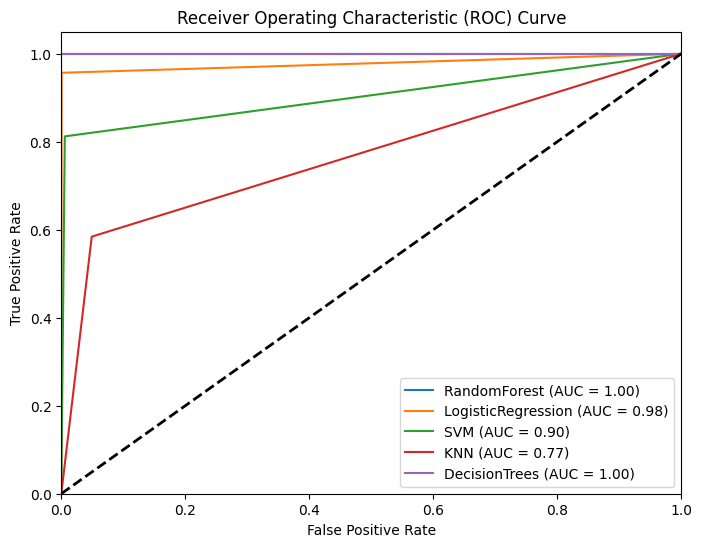

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Define the models and their predictions
models = {
    'RandomForest': (y_pred_rf, rf_classifier),
    'LogisticRegression': (y_pred_log_reg, log_reg),
    'SVM': (y_pred_svm, svm_classifier),
    'KNN': (y_pred_knn, knn_classifier),
    'DecisionTrees': (y_pred_dt, dt_classifier)
}

# Create a plot for ROC curves
plt.figure(figsize=(8, 6))
for model_name, (y_pred, model) in models.items():
    fpr, tpr, _ = roc_curve(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)  # Diagonal line for reference
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()
